# Problem 3.7

Consider the equation from Prob. 3.5 where we replace one of the coefficients with a parameter $a$ as follows:

$$r(u) = a u^3 - 6u^2 + 12u - 8 = 0.$$

a. Produce a plot similar to Fig. 3.12 by perturbing $a$ in the neighborhood of $a = 1.2$ using a solver convergence tolerance of $|r| \le 10^{-6}$.

b. *Exploration:* Try smaller tolerances and see how much you can decrease the numerical noise.

In [66]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [67]:
# implementation adapted from prob 3_5 with added factor a
a_default = 1.2 # global variable for the factor a

def residual(u, a=a_default):
    return a*u**3 - 6*u**2 + 12*u - 8

def derrivatie(u, a=a_default):
    return 3*a*u**2 - 12*u + 12

def solve_system(u0, max_iter=30, tol=1e-6, table=True):
    u = u0
    history = []                        # (iteration, u, residual)
    converged = False
    for i in range(max_iter):
        r = residual(u, a=a_default)
        history.append((i, u, r))       # update the history
        if abs(r) <= tol:               # converged when the residual is small
            converged = True            # stop iterating when r is below the tolerance
            break
        u = u - r / derrivatie(u, a=a_default)       # calculate u_k+1 for the next iteration

    if table:
        print(f"{'iter':>4} {'u':>14} {'r':>14}")
        for i_k, u_k, r_k in history:
            print(f"{i_k:4d} {u_k:14.8f} {r_k:14.8f}")
        print(f"{'converged' if converged else 'NOT converged'} after {i} iterations")
    return u, history

# quick test of the function
solve_system(2.0, table=True);

iter              u              r
   0     2.00000000     1.60000000
   1     1.33333333     0.17777778
   2     1.25925926    -0.00707209
   3     1.26198188    -0.00001085
   4     1.26198607    -0.00000000
converged after 4 iterations


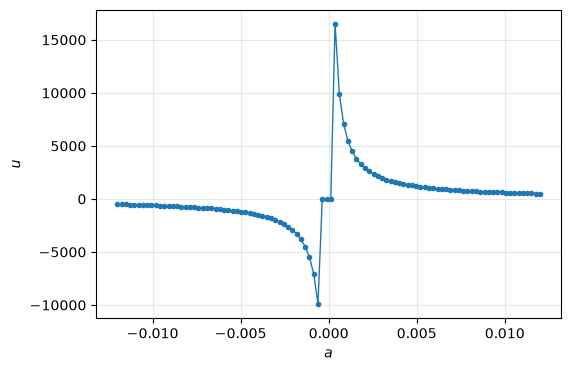

In [68]:
# a) perturbation of a around 1.2 and see how the solution changes
a_values = 1.2 * np.linspace(-0.01, 0.01, 100)

results = [] # a and corresponding u values

for a in a_values:
    a_default = a
    u, _ = solve_system(3.0, max_iter=100000, table=False)
    results.append((a, u))

a_arr, u_arr = np.array(results).T

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(a_arr, u_arr, "o-", ms=3, lw=1)
ax.set_xlabel("$a$")
ax.set_ylabel("$u$")
ax.grid(alpha=0.3)

plt.show()

a) interpretation  
with initial max iterations at 30 there was no major anomaly except for some small disturbances. but after raising the max iterations to 1000000 we can clearly see the value of u changing with respect to a. near a = 1.2 there is a clear divergence where u goes to negative and positive infinity similar to 1/x.

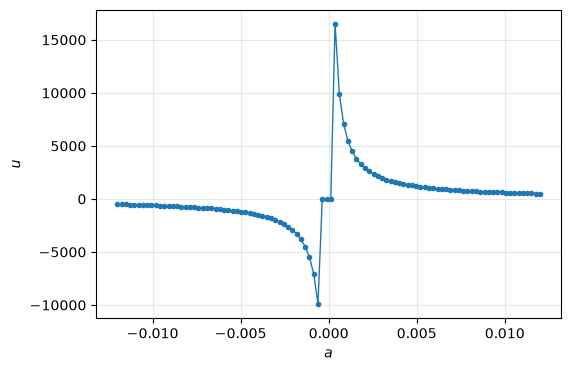

In [69]:
# b) smaller tolerance and see how the solution changes

a_values = 1.2 * np.linspace(-0.01, 0.01, 100)

results = [] # a and corresponding u values

for a in a_values:
    a_default = a
    u, _ = solve_system(3.0, max_iter=100000, tol=1e-9, table=False)
    results.append((a, u))

a_arr, u_arr = np.array(results).T

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(a_arr, u_arr, "o-", ms=3, lw=1)
ax.set_xlabel("$a$")
ax.set_ylabel("$u$")
ax.grid(alpha=0.3)

plt.show()

b) interpretation
there seems to be no difference in results when trying smaller tolerances.

## Results

see above

## Interpretation

the amount of iterations is a critical factor for solving system. if a system repetately runs into the iteration limit there might be an underlying problem or the limit needs to be raised.